# 06 · Monitoring: is the model still looking at the customers it was trained on?

The weekly pipeline (`nectar.pipeline.weekly`) compares each week's scoring population with the training population before it publishes a plan. A drift **ALERT** blocks publication, and the live plan stays in place. A **WARN** publishes but flags the model for retraining.

Drift is measured with the **Population Stability Index (PSI)**, the standard check in credit-risk model monitoring: under 0.10 is stable, 0.10–0.25 is a moderate shift, and above 0.25 is a major shift.

This notebook answers three questions:
1. How stable is the population across the two years of data?
2. Would the monitor catch a real shock, such as a cost-of-living squeeze?
3. Does drift in the inputs reach the model's decisions?

In [1]:
import os
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"
import warnings; warnings.filterwarnings("ignore")
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from nectar import viz
from nectar.viz import BLUE, ORANGE, GREY, TEXT_2
from nectar.config import ROOT
from nectar.features.offer_features import build_offer_features
from nectar.features.schema import model_matrix
from nectar.monitoring.drift import ReferenceProfile, compare, WARN_PSI, ALERT_PSI, PREDICTION

viz.set_style()
pd.set_option("display.float_format", "{:,.3f}".format)
model = joblib.load(ROOT / "models" / "champion.joblib")
train = build_offer_features(92)
profile = ReferenceProfile.fit(train, model.score(model_matrix(train)), source="training, cutoff week 92")
print(f"Reference: {profile.rows:,} member-offer rows, {profile.members:,} members")

Reference: 43,326 member-offer rows, 2,407 members


## 1. Drift across the history of the data

In [2]:
rows = []
for cut in range(42, 103, 5):
    f = build_offer_features(cut)
    rep = compare(profile, f, model.score(model_matrix(f)), label=f"week {cut}")
    s = rep.summary()
    top = rep.results[0]
    rows.append({"cutoff_week": cut, "status": s["status"], "max_feature_psi": s["max_feature_psi"],
                 "top_feature": top["feature"] if top["feature"] != PREDICTION else rep.results[1]["feature"],
                 "prediction_psi": s["prediction_psi"], "members": rep.current["members"]})
hist = pd.DataFrame(rows)
hist

,cutoff_week,status,max_feature_psi,top_feature,prediction_psi,members
0,42,alert,0.854,c_weeks_since_last,0.010,2410
1,47,alert,0.764,c_weeks_since_last,0.005,2391
2,52,alert,0.727,c_weeks_since_last,0.005,2387
3,57,warn,0.156,c_weeks_since_last,0.004,2388
4,62,ok,0.075,c_weeks_since_last,0.002,2387
5,67,ok,0.043,c_spend_per_week,0.002,2393
6,72,ok,0.027,c_spend_per_week,0.001,2395
7,77,ok,0.016,c_spend_per_week,0.001,2402
8,82,ok,0.011,c_spend_per_trip,0.001,2418
9,87,ok,0.006,c_spend_per_week,0.000,2413


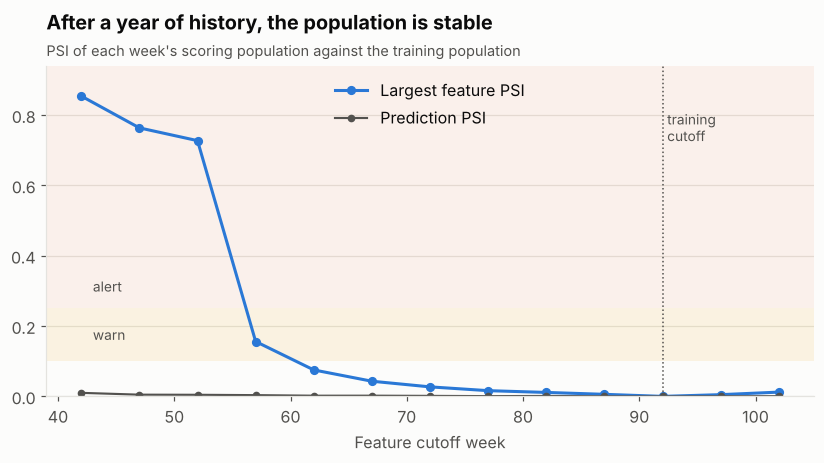

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.9))
ax.axhspan(WARN_PSI, ALERT_PSI, color="#eda100", alpha=0.10, lw=0)
ax.axhspan(ALERT_PSI, max(hist.max_feature_psi.max() * 1.1, 0.6), color=ORANGE, alpha=0.08, lw=0)
ax.plot(hist.cutoff_week, hist.max_feature_psi, color=BLUE, marker="o", ms=5, label="Largest feature PSI")
ax.plot(hist.cutoff_week, hist.prediction_psi, color=TEXT_2, marker="o", ms=4, lw=1.4, label="Prediction PSI")
ax.axvline(92, color=TEXT_2, lw=1, ls=":")
ax.text(92.4, hist.max_feature_psi.max() * 0.95, "training\ncutoff", fontsize=9, color=TEXT_2, va="top")
ax.text(43, (WARN_PSI + ALERT_PSI) / 2, "warn", fontsize=9, color=TEXT_2, va="center")
ax.text(43, ALERT_PSI * 1.25, "alert", fontsize=9, color=TEXT_2, va="center")
ax.set_ylim(0, max(hist.max_feature_psi.max() * 1.1, 0.6))
ax.set_xlabel("Feature cutoff week")
ax.set_title("After a year of history, the population is stable")
viz.subtitle(ax, "PSI of each week's scoring population against the training population")
ax.legend(loc="upper center")
viz.save(fig, "24_drift_history"); fig

Early cutoffs (weeks 42–57) are flagged because members have under a year of history: category habits like *share of trips* are still forming. From week 62 onwards every week is stable. The live cutoff (week 102) has a largest PSI of about 0.01. Prediction PSI stays near zero throughout.

**Two problems the monitor found in the pipeline itself (both fixed):**
- *Weeks since last category purchase* gave never-buyers a placeholder equal to the window length, which grows every week. It showed as drift at every cutoff. It is now capped at a fixed 75 weeks, the training window, so the training data is unchanged.
- Features were built from floating-point sums that DuckDB adds up in parallel, so two runs could differ in the last digits. Values on a bin edge then flipped bins. Money is now summed as exact decimals, so features are bit-for-bit reproducible.

## 2. Would it catch a real shock?

A simulated **cost-of-living squeeze**: members shop less often and spend less per trip, and lean harder on member prices. The squeeze is applied to the live (week 102) population with increasing severity.

In [4]:
live = build_offer_features(102)
def squeeze(df, s):
    d = df.copy()
    for c in ["m_spend_per_week", "m_median_basket", "c_spend_per_week", "c_spend_per_trip"]:
        d[c] = d[c] * (1 - s)
    for c in ["m_trips_per_week", "m_trips_per_week_13w"]:
        d[c] = d[c] * (1 - s / 2)
    d["m_member_discount_rate"] = (d.m_member_discount_rate * (1 + s)).clip(0, 1)
    return d

shock = []
for s in [0, 0.05, 0.10, 0.15, 0.20, 0.30]:
    f = squeeze(live, s)
    rep = compare(profile, f, model.score(model_matrix(f)))
    sm = rep.summary()
    shock.append({"squeeze_share": s, "status": sm["status"], "max_feature_psi": sm["max_feature_psi"],
                  "prediction_psi": sm["prediction_psi"], "features_drifted": len(sm["features_drifted"]),
                  "share_recommended": float((model.score(model_matrix(f)) > 0).mean())})
shock = pd.DataFrame(shock)
shock

,squeeze_share,status,max_feature_psi,prediction_psi,features_drifted,share_recommended
0,0.000,ok,0.012,0.001,0,0.281
1,0.050,ok,0.020,0.003,0,0.304
2,0.100,ok,0.084,0.015,0,0.332
3,0.150,warn,0.178,0.040,2,0.364
4,0.200,alert,0.292,0.075,2,0.393
5,0.300,alert,0.581,0.177,5,0.450


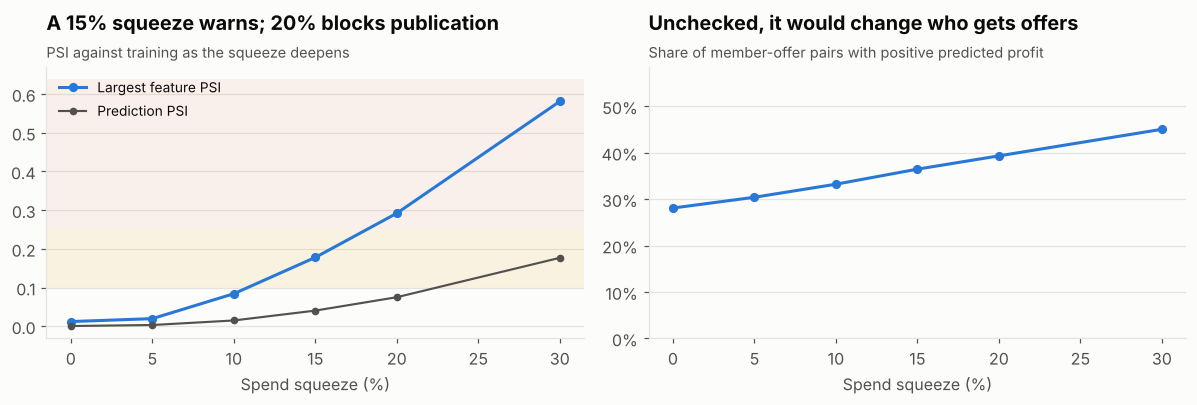

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
x = shock.squeeze_share * 100
ax = axes[0]
ax.axhspan(WARN_PSI, ALERT_PSI, color="#eda100", alpha=0.10, lw=0)
ax.axhspan(ALERT_PSI, shock.max_feature_psi.max() * 1.1, color=ORANGE, alpha=0.08, lw=0)
ax.plot(x, shock.max_feature_psi, color=BLUE, marker="o", ms=5, label="Largest feature PSI")
ax.plot(x, shock.prediction_psi, color=TEXT_2, marker="o", ms=4, lw=1.4, label="Prediction PSI")
ax.set_xlabel("Spend squeeze (%)")
ax.set_title("A 15% squeeze warns; 20% blocks publication")
viz.subtitle(ax, "PSI against training as the squeeze deepens")
ax.legend(loc="upper left", fontsize=9)

ax = axes[1]
ax.plot(x, shock.share_recommended, color=BLUE, marker="o", ms=5)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
ax.set_ylim(0, max(shock.share_recommended) * 1.3)
ax.set_xlabel("Spend squeeze (%)")
ax.set_title("Unchecked, it would change who gets offers")
viz.subtitle(ax, "Share of member-offer pairs with positive predicted profit")
fig.tight_layout()
viz.save(fig, "25_drift_shock"); fig

In [6]:
first_alert = shock.loc[shock.status == "alert", "squeeze_share"].min()
print(f"The pipeline would block publication from a {first_alert:.0%} squeeze onwards.")

The pipeline would block publication from a 20% squeeze onwards.


## Summary

| Question | Answer |
|---|---|
| Is the live population stable? | Yes. Largest PSI ≈ 0.01 at week 102, and every cutoff from week 62 onwards is OK |
| Would a shock be caught? | Yes. A 10% squeeze stays within normal variation, 15% raises a WARN, and 20% or more raises an ALERT that blocks publication |
| Does input drift reach decisions? | Yes. At a 30% squeeze, the share of pairs the model would offer rises from 28% to 45%, so a model that is never checked would quietly change who gets discounts |
| What did monitoring find on day one? | A placeholder value tied to the window length, and non-reproducible float sums. Both are now fixed |

**Operating rule:** ALERT → keep the live plan, investigate, and retrain on recent data (re-run the randomised test if behaviour has changed). WARN → publish, and schedule retraining within the month.